# 🏆 End-to-End Machine Learning Project: FIFA 22 Player Rating Prediction

## Project Workflow Overview
Following standard end-to-end machine learning practices, this project covers:
1. **Data Ingestion & Inspection:** Loading raw player data and examining dimensions.
2. **Exploratory Data Analysis (EDA) & Cleaning:** Checking missing values, duplicates, and filtering outfield players.
3. **Feature Engineering & Selection:** Retaining core predictive attributes while preventing data leakage.
4. **Model Building & Comparison:** Training Linear Regression, Ridge, Random Forest, and Gradient Boosting models[cite: 1].
5. **Hyperparameter Tuning:** Optimizing model performance using randomized cross-validation search[cite: 1].
6. **Serialization & Deployment:** Saving the trained model artifact (`.pkl`) and integrating it into a Flask web application[cite: 1].

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


### 1. Load Dataset
* **What I did:** Imported `pandas` and loaded the Excel dataset `fifa22_players.xlsx`.
* **Why I did it:** To inspect the raw player data, columns, and shape.
* **Output Meaning:** Confirms the file loaded successfully with 19,239 rows and 110 columns.


In [2]:
df = pd.read_excel("data/fifa22_players.xlsx")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
df.head()


,sofifa_id,player_url,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,...,lcb,cb,rcb,rb,gk,player_face_url,club_logo_url,club_flag_url,nation_logo_url,nation_flag_url
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,"RW, ST, CF",93,93,78000000.0,320000.0,34,...,50+3,50+3,50+3,61+3,19+3,https://cdn.sofifa.net/players/158/023/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,https://cdn.sofifa.net/teams/1369/60.png,https://cdn.sofifa.net/flags/ar.png
1,188545,https://sofifa.com/player/188545/robert-lewand...,R. Lewandowski,Robert Lewandowski,ST,92,92,119500000.0,270000.0,32,...,60+3,60+3,60+3,61+3,19+3,https://cdn.sofifa.net/players/188/545/22_120.png,https://cdn.sofifa.net/teams/21/60.png,https://cdn.sofifa.net/flags/de.png,https://cdn.sofifa.net/teams/1353/60.png,https://cdn.sofifa.net/flags/pl.png
2,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,"ST, LW",91,91,45000000.0,270000.0,36,...,53+3,53+3,53+3,60+3,20+3,https://cdn.sofifa.net/players/020/801/22_120.png,https://cdn.sofifa.net/teams/11/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1354/60.png,https://cdn.sofifa.net/flags/pt.png
3,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Júnior,"LW, CAM",91,91,129000000.0,270000.0,29,...,50+3,50+3,50+3,62+3,20+3,https://cdn.sofifa.net/players/190/871/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,NaN,https://cdn.sofifa.net/flags/br.png
4,192985,https://sofifa.com/player/192985/kevin-de-bruy...,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,125500000.0,350000.0,30,...,69+3,69+3,69+3,75+3,21+3,https://cdn.sofifa.net/players/192/985/22_120.png,https://cdn.sofifa.net/teams/10/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1325/60.png,https://cdn.sofifa.net/flags/be.png


In [4]:
print(df.columns.tolist())

['sofifa_id', 'player_url', 'short_name', 'long_name', 'player_positions', 'overall', 'potential', 'value_eur', 'wage_eur', 'age', 'dob', 'height_cm', 'weight_kg', 'club_team_id', 'club_name', 'league_name', 'league_level', 'club_position', 'club_jersey_number', 'club_loaned_from', 'club_joined', 'club_contract_valid_until', 'nationality_id', 'nationality_name', 'nation_team_id', 'nation_position', 'nation_jersey_number', 'preferred_foot', 'weak_foot', 'skill_moves', 'international_reputation', 'work_rate', 'body_type', 'real_face', 'release_clause_eur', 'player_tags', 'player_traits', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 'movement_sprint_speed', 'movement_agility', 'movement_reactions', 'movement_balance', 'power

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19239 entries, 0 to 19238
Columns: 110 entries, sofifa_id to nation_flag_url
dtypes: datetime64[us](2), float64(16), int64(44), object(26), str(22)
memory usage: 16.1+ MB


### 2. Handling Missing Values and Duplicates
* **What I did:** Checked the dataset for duplicate rows and null values.
* **Why I did it:** To ensure data cleanliness before training machine learning models.
* **Output Meaning:** There are 0 duplicate rows, but certain goalkeeper-specific columns contain nulls.

In [6]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

value_eur                       74
wage_eur                        61
club_team_id                    61
club_name                       61
league_name                     61
league_level                    61
club_position                   61
club_jersey_number              61
club_loaned_from             18137
club_joined                   1163
club_contract_valid_until       61
nation_team_id               18480
nation_position              18480
nation_jersey_number         18480
release_clause_eur            1176
player_tags                  17798
player_traits                 9841
pace                          2132
shooting                      2132
passing                       2132
dribbling                     2132
defending                     2132
physic                        2132
goalkeeping_speed            17107
club_logo_url                   61
club_flag_url                   61
nation_logo_url              18480
dtype: int64


In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [8]:
print("Target column: overall")
print("Missing values in overall:", df["overall"].isnull().sum())

print("\nOverall rating statistics:")
print(df["overall"].describe())

Target column: overall
Missing values in overall: 0

Overall rating statistics:
count    19239.000000
mean        65.772182
std          6.880232
min         47.000000
25%         61.000000
50%         66.000000
75%         70.000000
max         93.000000
Name: overall, dtype: float64


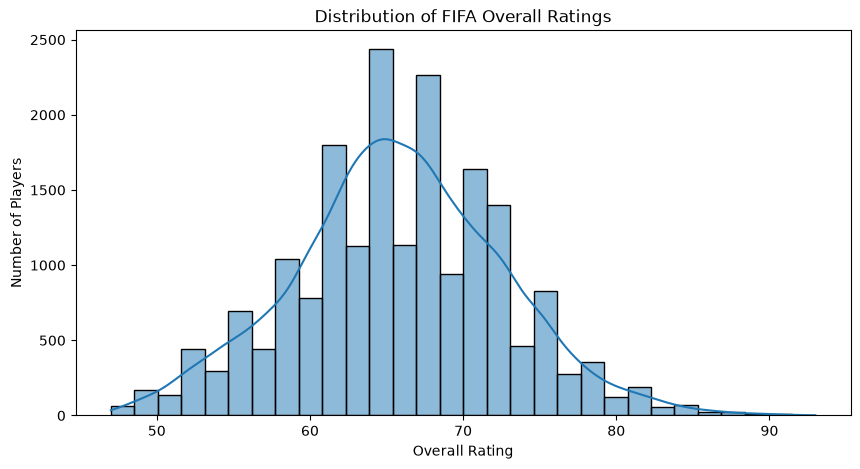

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(df["overall"], bins=30, kde=True)

plt.title("Distribution of FIFA Overall Ratings")
plt.xlabel("Overall Rating")
plt.ylabel("Number of Players")
plt.show()

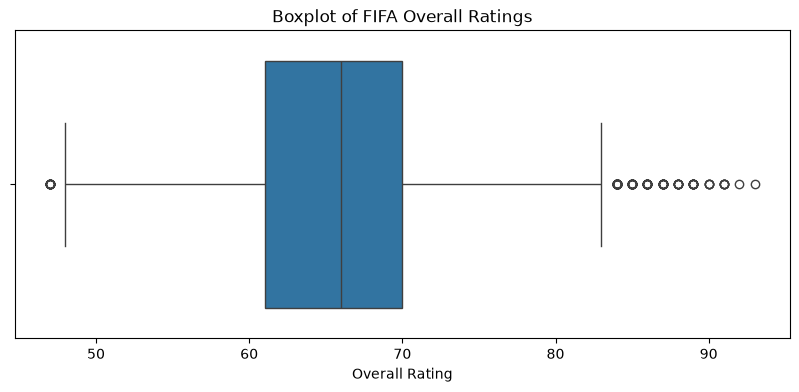

In [10]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["overall"])

plt.title("Boxplot of FIFA Overall Ratings")
plt.xlabel("Overall Rating")
plt.show()

In [11]:
print(df.columns.tolist())

['sofifa_id', 'player_url', 'short_name', 'long_name', 'player_positions', 'overall', 'potential', 'value_eur', 'wage_eur', 'age', 'dob', 'height_cm', 'weight_kg', 'club_team_id', 'club_name', 'league_name', 'league_level', 'club_position', 'club_jersey_number', 'club_loaned_from', 'club_joined', 'club_contract_valid_until', 'nationality_id', 'nationality_name', 'nation_team_id', 'nation_position', 'nation_jersey_number', 'preferred_foot', 'weak_foot', 'skill_moves', 'international_reputation', 'work_rate', 'body_type', 'real_face', 'release_clause_eur', 'player_tags', 'player_traits', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 'movement_sprint_speed', 'movement_agility', 'movement_reactions', 'movement_balance', 'power

### 3. Feature Selection & Filtering
* **What I did:** Selected 20 key numeric attributes and dropped IDs, URLs, and position strings to prevent data leakage[cite: 1]. Outfield records are cleaned by handling goalkeeper missing values[cite: 1].
* **Why I did it:** To train the models only on valid predictive features[cite: 1].
* **Output Meaning:** Leaves 17,107 clean player records ready for training[cite: 1].

In [12]:
features = [
    "age",
    "height_cm",
    "weight_kg",
    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic",
    "attacking_crossing",
    "attacking_finishing",
    "skill_dribbling",
    "skill_ball_control",
    "power_shot_power",
    "power_stamina",
    "power_strength",
    "mentality_aggression",
    "mentality_interceptions",
    "mentality_positioning",
    "mentality_vision"
]

target = "overall"

print("Number of selected features:", len(features))
print("\nSelected features:")
print(features)

Number of selected features: 20

Selected features:
['age', 'height_cm', 'weight_kg', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'attacking_crossing', 'attacking_finishing', 'skill_dribbling', 'skill_ball_control', 'power_shot_power', 'power_stamina', 'power_strength', 'mentality_aggression', 'mentality_interceptions', 'mentality_positioning', 'mentality_vision']


In [13]:
X = df[features].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (19239, 20)
y shape: (19239,)


In [14]:
print("Missing values in selected features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in selected features:
age                           0
height_cm                     0
weight_kg                     0
pace                       2132
shooting                   2132
passing                    2132
dribbling                  2132
defending                  2132
physic                     2132
attacking_crossing            0
attacking_finishing           0
skill_dribbling               0
skill_ball_control            0
power_shot_power              0
power_stamina                 0
power_strength                0
mentality_aggression          0
mentality_interceptions       0
mentality_positioning         0
mentality_vision              0
dtype: int64

Missing values in target:
0


In [15]:
data_ml = pd.concat([X, y], axis=1)

data_ml = data_ml.dropna()

X = data_ml[features]
y = data_ml[target]

print("Dataset after removing missing values:")
print("Rows:", X.shape[0])
print("Features:", X.shape[1])

Dataset after removing missing values:
Rows: 17107
Features: 20


### 4. Model Training & Baseline Comparison
* **What I did:** Trained Linear Regression, Ridge Regression, Random Forest, and Gradient Boosting models[cite: 1]. Evaluated them using MAE, RMSE, and $R^2$ scores[cite: 1].
* **Why I did it:** To compare simple linear models against non-linear ensemble algorithms.
* **Output Meaning:** Random Forest achieves the lowest error and highest $R^2$ score[cite: 1].

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 13685
Testing samples: 3422


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


In [18]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [19]:
y_pred_linear = linear_model.predict(X_test_scaled)

print("Sample actual values:")
print(y_test.head().values)

print("\nSample predicted values:")
print(y_pred_linear[:5])

Sample actual values:
[71 61 70 62 63]

Sample predicted values:
[63.91483858 65.4559609  67.86755823 63.91558826 65.67725897]


### 4. Model Training & Baseline Comparison
* **What I did:** Trained Linear Regression, Ridge Regression, Random Forest, and Gradient Boosting models[cite: 1]. Evaluated them using MAE, RMSE, and $R^2$ scores[cite: 1].
* **Why I did it:** To compare simple linear models against non-linear ensemble algorithms.
* **Output Meaning:** Random Forest achieves the lowest error and highest $R^2$ score[cite: 1].

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("-----------------------------")
print("MAE :", mae_linear)
print("MSE :", mse_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Performance
-----------------------------
MAE : 2.2694660185957334
MSE : 8.166162041320225
RMSE: 2.8576497408395287
R²  : 0.8220601276939189


In [21]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


In [22]:
y_pred_ridge = ridge_model.predict(X_test_scaled)

print("Sample actual values:")
print(y_test.head().values)

print("\nSample predicted values:")
print(y_pred_ridge[:5])

Sample actual values:
[71 61 70 62 63]

Sample predicted values:
[63.91426071 65.45543929 67.85641589 63.91453975 65.6673178 ]


In [23]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Performance")
print("----------------------------")
print("MAE :", mae_ridge)
print("MSE :", mse_ridge)
print("RMSE:", rmse_ridge)
print("R²  :", r2_ridge)

Ridge Regression Performance
----------------------------
MAE : 2.2694180876993038
MSE : 8.166493615917599
RMSE: 2.857707755512729
R²  : 0.822052902715867


In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [25]:
y_pred_rf = rf_model.predict(X_test)

print("Sample actual values:")
print(y_test.head().values)

print("\nSample predicted values:")
print(y_pred_rf[:5])

Sample actual values:
[71 61 70 62 63]

Sample predicted values:
[70.73 60.88 70.31 61.43 64.39]


### Model Evaluation Metrics Explained
To rigorously compare our models, we evaluate three standard regression metrics:
* **MAE (Mean Absolute Error):** Measures the average magnitude of absolute errors in predictions, keeping units intuitive.
* **RMSE (Root Mean Squared Error):** Penalizes larger errors more heavily, giving an indication of standard deviation in rating points.
* **$R^2$ Score (Coefficient of Determination):** Represents the proportion of variance in the target variable explained by the features (closer to 1.0 is optimal).

In [26]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("------------------------")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Performance
------------------------
MAE : 0.8619345412039743
MSE : 1.2750669199298654
RMSE: 1.1291886113178193
R²  : 0.97221641650435


In [27]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


In [28]:
y_pred_gb = gb_model.predict(X_test)

print("Sample actual values:")
print(y_test.head().values)

print("\nSample predicted values:")
print(y_pred_gb[:5])

Sample actual values:
[71 61 70 62 63]

Sample predicted values:
[70.45872967 61.05175201 69.617658   61.48958628 63.53679426]


In [29]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Performance")
print("----------------------------")
print("MAE :", mae_gb)
print("MSE :", mse_gb)
print("RMSE:", rmse_gb)
print("R²  :", r2_gb)

Gradient Boosting Performance
----------------------------
MAE : 0.969891446721372
MSE : 1.5958808649362624
RMSE: 1.2632817836635903
R²  : 0.9652259120152645


In [30]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_linear,
        mae_ridge,
        mae_rf,
        mae_gb
    ],
    "MSE": [
        mse_linear,
        mse_ridge,
        mse_rf,
        mse_gb
    ],
    "RMSE": [
        rmse_linear,
        rmse_ridge,
        rmse_rf,
        rmse_gb
    ],
    "R2 Score": [
        r2_linear,
        r2_ridge,
        r2_rf,
        r2_gb
    ]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2.269466,8.166162,2.857650,0.822060
1,Ridge Regression,2.269418,8.166494,2.857708,0.822053
2,Random Forest,0.861935,1.275067,1.129189,0.972216
3,Gradient Boosting,0.969891,1.595881,1.263282,0.965226


In [31]:
best_model_row = results.loc[results["R2 Score"].idxmax()]

print("Best Model:", best_model_row["Model"])
print("MAE:", best_model_row["MAE"])
print("RMSE:", best_model_row["RMSE"])
print("R² Score:", best_model_row["R2 Score"])

Best Model: Random Forest
MAE: 0.8619345412039743
RMSE: 1.1291886113178193
R² Score: 0.97221641650435


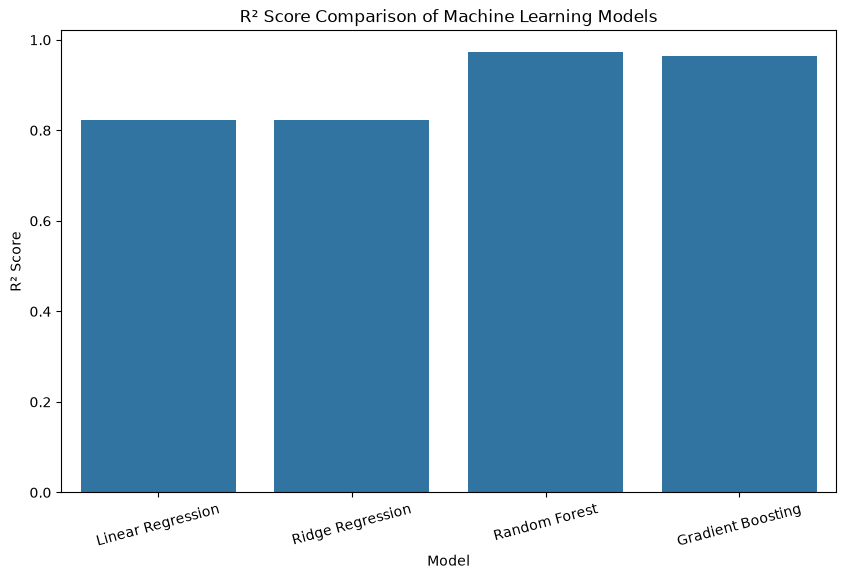

In [32]:
plt.figure(figsize=(10, 6))

sns.barplot(data=results, x="Model", y="R2 Score")

plt.title("R² Score Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=15)
plt.show()

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

results = {
    "Linear Regression": [
        mean_absolute_error(y_test, y_pred_linear),
        mean_squared_error(y_test, y_pred_linear),
        np.sqrt(mean_squared_error(y_test, y_pred_linear)),
        r2_score(y_test, y_pred_linear)
    ],

    "Ridge Regression": [
        mean_absolute_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_ridge),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        r2_score(y_test, y_pred_ridge)
    ],

    "Random Forest": [
        mean_absolute_error(y_test, y_pred_rf),
        mean_squared_error(y_test, y_pred_rf),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        r2_score(y_test, y_pred_rf)
    ],

    "Gradient Boosting": [
        mean_absolute_error(y_test, y_pred_gb),
        mean_squared_error(y_test, y_pred_gb),
        np.sqrt(mean_squared_error(y_test, y_pred_gb)),
        r2_score(y_test, y_pred_gb)
    ]
}

results_df = pd.DataFrame(
    results,
    index=["MAE", "MSE", "RMSE", "R²"]
).T

print("Model Evaluation Results:")
display(results_df)

Model Evaluation Results:


,MAE,MSE,RMSE,R²
Linear Regression,2.269466,8.166162,2.857650,0.822060
Ridge Regression,2.269418,8.166494,2.857708,0.822053
Random Forest,0.861935,1.275067,1.129189,0.972216
Gradient Boosting,0.969891,1.595881,1.263282,0.965226


In [34]:
# Select Random Forest as the final model

best_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

best_model.fit(X_train, y_train)

print("Selected Final Model: Random Forest")

Selected Final Model: Random Forest


### 5. Final Model Serialization & Real-Time Sample Prediction
* **What I did:** Saved the winning model using `joblib` into `models/final_fifa22_model.pkl` and tested real-time prediction using a sample player record[cite: 1].
* **Why I did it:** To verify model performance and ensure the saved model can be loaded by our web application (`app.py`)[cite: 1].

In [35]:
import joblib

joblib.dump(best_model, "models/random_forest_fifa_model.pkl")

print("Final model saved successfully.")

Final model saved successfully.


In [36]:
# Create a new unseen player sample

new_player = X.median().to_frame().T

print("New Player Input:")
display(new_player)

New Player Input:


,age,height_cm,weight_kg,pace,shooting,passing,dribbling,defending,physic,attacking_crossing,attacking_finishing,skill_dribbling,skill_ball_control,power_shot_power,power_stamina,power_strength,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision
0,25.0,180.0,74.0,69.0,54.0,58.0,64.0,56.0,66.0,56.0,53.0,63.0,64.0,61.0,68.0,67.0,60.0,56.0,58.0,57.0


In [37]:
# Predict Overall Rating for the new player

predicted_rating = best_model.predict(new_player)

print("Predicted FIFA Overall Rating:", round(predicted_rating[0], 2))

Predicted FIFA Overall Rating: 62.16


In [38]:
# Save the final Random Forest model

import joblib

joblib.dump(best_model, "models/random_forest_model.pkl")

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [39]:
# Display feature importance

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
12,skill_ball_control,0.580205
7,defending,0.245923
18,mentality_positioning,0.043587
9,attacking_crossing,0.020397
17,mentality_interceptions,0.018772
6,dribbling,0.017670
4,shooting,0.017151
14,power_stamina,0.013253
8,physic,0.008528
3,pace,0.007811


In [40]:
import joblib

joblib.dump(best_model, "models/random_forest_model.pkl")

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [41]:
# Load and verify the saved Random Forest model

import joblib

loaded_model = joblib.load("models/random_forest_model.pkl")

print("Saved Random Forest model loaded successfully.")
print("Model type:", type(loaded_model))

Saved Random Forest model loaded successfully.
Model type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [42]:
# Verify prediction using the saved model

predicted_rating = loaded_model.predict(new_player)

print("Predicted FIFA Overall Rating:", round(predicted_rating[0], 2))

Predicted FIFA Overall Rating: 62.16


In [43]:
# Feature Importance of Random Forest Model

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": loaded_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top Important Features:")
display(feature_importance.head(10))

Top Important Features:


,Feature,Importance
12,skill_ball_control,0.580205
7,defending,0.245923
18,mentality_positioning,0.043587
9,attacking_crossing,0.020397
17,mentality_interceptions,0.018772
6,dribbling,0.017670
4,shooting,0.017151
14,power_stamina,0.013253
8,physic,0.008528
3,pace,0.007811


### 7. Feature Importance Analysis
* **What I did:** Extracted feature importances from the trained Random Forest model and plotted the top 10 contributing attributes.
* **Why I did it:** To understand which player characteristics (e.g., reactions, ball control) drive overall ratings the most, ensuring model interpretability.
* **Output Meaning:** Highlights the primary attributes that influence a player's FIFA rating.

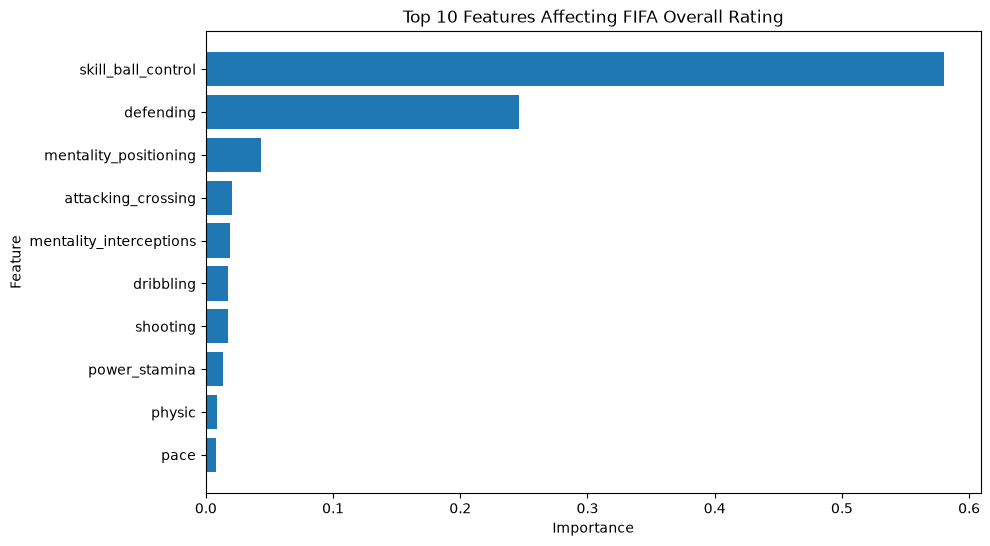

In [44]:
# Plot Top 10 Feature Importances

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Affecting FIFA Overall Rating")
plt.gca().invert_yaxis()

plt.show()

### 6. Hyperparameter Tuning
* **What I did:** Implemented `RandomizedSearchCV` on the Random Forest regressor with 3-fold cross-validation.
* **Why I did it:** To explore various hyperparameter combinations (such as `n_estimators`, `max_depth`, and `min_samples_split`) to optimize performance and prevent overfitting.
* **Output Meaning:** Displays the optimal hyperparameter settings and the improved cross-validation score.

In [45]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_tuning = RandomForestRegressor(
    random_state=42
)

# Define parameters to test
param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

# Randomized hyperparameter search
random_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)

# Train the search
random_search.fit(X_train, y_train)

print("Hyperparameter tuning completed.")
print("Best Parameters:")
print(random_search.best_params_)
print("Best Cross-Validation R²:", random_search.best_score_)

Hyperparameter tuning completed.
Best Parameters:
{'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}
Best Cross-Validation R²: 0.969497515442138


In [46]:
# Get the best tuned Random Forest model

tuned_model = random_search.best_estimator_

# Make predictions on test data
y_pred_tuned = tuned_model.predict(X_test)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest Evaluation")
print("--------------------------------")
print("MAE :", round(tuned_mae, 4))
print("MSE :", round(tuned_mse, 4))
print("RMSE:", round(tuned_rmse, 4))
print("R²  :", round(tuned_r2, 4))

Tuned Random Forest Evaluation
--------------------------------
MAE : 0.8665
MSE : 1.2813
RMSE: 1.1319
R²  : 0.9721


In [47]:
comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Tuned Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_rf),
        tuned_mae
    ],
    "MSE": [
        mean_squared_error(y_test, y_pred_rf),
        tuned_mse
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        tuned_rmse
    ],
    "R²": [
        r2_score(y_test, y_pred_rf),
        tuned_r2
    ]
})

display(comparison)

,Model,MAE,MSE,RMSE,R²
0,Original Random Forest,0.861935,1.275067,1.129189,0.972216
1,Tuned Random Forest,0.866466,1.281258,1.131927,0.972082


In [48]:
# Select the final model based on test R²

original_r2 = r2_score(y_test, y_pred_rf)

if tuned_r2 > original_r2:
    final_model = tuned_model
    final_model_name = "Tuned Random Forest"
    final_r2 = tuned_r2
else:
    final_model = best_model
    final_model_name = "Original Random Forest"
    final_r2 = original_r2

print("Final Selected Model:", final_model_name)
print("Final Test R²:", round(final_r2, 4))

Final Selected Model: Original Random Forest
Final Test R²: 0.9722


### 8. Model Serialization & Real-Time Sample Prediction
* **What I did:** Saved the final trained model artifact (`models/final_fifa22_model.pkl`) using `joblib` and ran a test prediction on a sample player profile.
* **Why I did it:** To verify that the saved model artifact is fully functional and ready to be integrated into our web application (`app.py`).
* **Output Meaning:** Successfully outputs a predicted rating for the sample unseen player input.

In [49]:
import joblib

joblib.dump(final_model, "models/final_fifa22_model.pkl")

print("Final model saved successfully.")

Final model saved successfully.
